In [1]:
suppressMessages({
library(RNetCDF)
library(dplyr)
library(ggplot2)
library(parallel)
library(dataRetrieval)
library(arrow)
library(lubridate)
library(tidyr)
library(broom)
library(IRdisplay)
library(data.table)

})
                 

In [2]:
make_SOS_df=0
make_model_df =0 # 1 just build errors, #2 build model dataframe as well
make_USGS_df = 0
source('/nas/cee-water/cjgleason/colin/Batesian_Validation/Prepare_data.R')
source('/nas/cee-water/cjgleason/colin/Batesian_Validation/prepare_models.R')

runID <- 'Heejin_v5'
# fixed anonymization: never changes with a seed
# fixed anonymization: never changes with a seed
algo_key <- tibble(
  algo   = c("metroman", "sad", "consensus", "momma", "busboi", "sic4dvar",
             "CaMaFlood", "dHBV2", "physics_ensemble", "GLOFAS_HRR",
             "GradesHydroDL", "hymap", "ML_ensemble", "ERA5_rapid"),
  model  = LETTERS[1:14],
  source = rep(c("SoS", "model"), c(6, 8)))


USGS_df <- get_USGS(make_USGS_df, paste0(base, 'USGS data/USGS Parquets/'), paste0(base, 'USGS.parquet'))

xwalk <- make_xwalk(paste0(base, 'OG attempt/ADCP_compiled.csv'))

sos_hydrographs <- get_SOS(make_SOS_df,
  '/nas/cee-water/cjgleason/heejin/SWOT_Confluence/run-confluence/confluence_RF_consensus/RF_consensus_mnt/output_bugfix/sos/',
  	algo_key$algo[algo_key$source == "SoS"], paste0(base, 'sos_hydrographs_', runID, '.parquet'))

sos_hydrographs <- add_sos_CI(sos_hydrographs,
     uat_file  = '/nas/cee-water/cjgleason/colin/Batesian_Validation/UAT_stats.parquet',
     sos_algos = algo_key$algo[algo_key$source == "SoS"])

model_hydrographs <- get_models(make_model_df, xwalk,
  model_dir     = '/nas/cee-water/cjgleason/colin/SWOT_global_Q_paper/daily_ensembles_versionD/',
  out_file      = paste0(base, 'model_hydrographs_', runID, '.parquet'),
  error_file    = paste0(base, 'quantile_errors.parquet'),
  svs_dir       = base,
  SWORD_version = '17b',
  probs         = c(0.16, 0.84),
  n_cores       = 44)

In [3]:
#match SWOT to the nearest 15 minutes and join to SOS
sos_USGS_A15 <- xwalk %>%
  right_join(sos_hydrographs, by = "reach_id", relationship = "one-to-many") %>%
  mutate(sos_row = row_number(),
         lo = time - minutes(30),
         hi = time + minutes(30)) %>%

  inner_join(USGS_df %>%
            filter(!is.na(Q_approved)) %>%
           select(USGS_ID, usgs_time = time,
                   Q_A15 = Q_approved, Q_central_A15 = Q_central,
                   Q_lower_A15 = Q_lower, Q_upper_A15 = Q_upper),
             by = join_by(USGS_ID, between(y$usgs_time, x$lo, x$hi))) %>%

  mutate(dt_min = abs(as.numeric(difftime(time, usgs_time, units = "mins")))) %>%
  arrange(sos_row, dt_min) %>%
  distinct(sos_row, .keep_all = TRUE) %>%
  select(-sos_row, -lo, -hi)



In [4]:
#match SWOT to the nearest field measurement within 30 minutes
sos_USGS_M15 <- xwalk %>%
  right_join(sos_hydrographs, by = "reach_id", relationship = "one-to-many") %>%
  mutate(sos_row = row_number(),
         lo = time - minutes(30),
         hi = time + minutes(30)) %>%

  inner_join(USGS_df %>%
            filter(!is.na(Q_measured)) %>%
            select(USGS_ID, usgs_time = time, Q_M15 = Q_measured) %>%
            mutate(Q_lower_M15 = Q_M15 * 0.95,     # ADCP error, USGS protocol
                   Q_upper_M15 = Q_M15 * 1.05),
             by = join_by(USGS_ID, between(y$usgs_time, x$lo, x$hi))) %>%

  mutate(dt_min = abs(as.numeric(difftime(time, usgs_time, units = "mins")))) %>%
  arrange(sos_row, dt_min) %>%
  distinct(sos_row, .keep_all = TRUE) %>%
  select(-sos_row, -lo, -hi)



In [5]:
# gauge: daily mean, band half-widths combined in quadrature (error of the mean)
usgs_A24 <- USGS_df %>%
  filter(!is.na(Q_approved), !is.na(Q_central), !is.na(Q_lower), !is.na(Q_upper)) %>%
  mutate(date = as.Date(time, tz = "UTC")) %>%
  group_by(USGS_ID, date) %>%
  summarise(n_obs          = n(),
            Q_A24          = mean(Q_approved),
            Q_central_A24  = mean(Q_central),
            #we can either estimate the uncertainty on the mean assuming independent errors, which is false,
            #or fully acorrelated erors. in that case, the bounds become
            Q_upper_A24    = Q_central_A24 + mean(Q_upper - Q_central),
            Q_lower_A24    = Q_central_A24 - mean(Q_central - Q_lower),
            .groups = "drop")

sos_algos <- algo_key$algo[algo_key$source == "SoS"]

sos_A24 <- sos_hydrographs %>%
  filter(reach_id %in% xwalk$reach_id) %>%
  mutate(date = as.Date(time, tz = "UTC")) %>%
  group_by(reach_id, date) %>%
  summarise(across(all_of(c(sos_algos,
                            paste0(sos_algos, "_lower_CI"),
                            paste0(sos_algos, "_upper_CI"))),
                   ~ if (all(is.na(.x))) NA_real_ else mean(.x, na.rm = TRUE)),
            .groups = "drop")

model_A24 <- model_hydrographs %>%
  filter(reach_id %in% xwalk$reach_id) %>%
  pivot_wider(id_cols = c(reach_id, date), names_from = model,
              values_from = c(model_Q, lower_CI, upper_CI),
              names_glue = "{model}_{.value}") %>%
  rename_with(~ sub("_model_Q$", "", .x), ends_with("_model_Q"))

sos_USGS_A24 <- xwalk %>%
  inner_join(usgs_A24, by = "USGS_ID", relationship = "one-to-many") %>%
  left_join(sos_A24,   by = c("reach_id", "date"), relationship = "one-to-one") %>%
  left_join(model_A24, by = c("reach_id", "date"), relationship = "one-to-one") %>%
  mutate(time = date)



In [6]:
#lmit to common times for ranking
sos_USGS_A15 <- keep_common_dates(sos_USGS_A15, algo_key$algo[algo_key$source == "SoS"])
sos_USGS_A24 <- keep_common_dates(sos_USGS_A24, algo_key$algo)
sos_USGS_M15 <- keep_common_dates(sos_USGS_M15, algo_key$algo[algo_key$source == "SoS"])

In [7]:
source('/nas/cee-water/cjgleason/colin/Batesian_Validation/validate.R')

sos_trad_A15 =do.call(rbind, lapply(	algo_key$algo[algo_key$source == "SoS"], validate_algo,
                                         joined_df  = sos_USGS_A15,
                                         truth_col  = "Q_A15",
                                         lower_col  = "Q_lower_A15",
                                         upper_col  = "Q_upper_A15",
                                         xwalk      = xwalk,
                                         val_type   = "trad",
                                         truth_type = "A15"))

sos_bates_A15 =do.call(rbind, lapply(	algo_key$algo[algo_key$source == "SoS"], validate_algo,
                                         joined_df  = sos_USGS_A15,
                                         truth_col  = "Q_central_A15",
                                         lower_col  = "Q_lower_A15",
                                         upper_col  = "Q_upper_A15",
                                         xwalk      = xwalk,
                                         val_type   = "Batesian",
                                         truth_type = "A15"))


sos_trad_A24 <- do.call(rbind, lapply(	algo_key$algo, validate_algo,
                                         joined_df  = sos_USGS_A24,
                                         truth_col  = "Q_A24",
                                         lower_col  = "Q_lower_A24",
                                         upper_col  = "Q_upper_A24",
                                         xwalk      = xwalk,
                                         val_type   = "trad",
                                         truth_type = "A24"))

sos_bates_A24 <- do.call(rbind, lapply(algo_key$algo, validate_algo,
                                       joined_df  = sos_USGS_A24,
                                       truth_col  = "Q_central_A24",
                                       lower_col  = "Q_lower_A24",
                                       upper_col  = "Q_upper_A24",
                                       xwalk      = xwalk,
                                       val_type   = "Batesian",
                                       truth_type = "A24"))



In [8]:
sos_algos <- algo_key$algo[algo_key$source == "SoS"]

sos_USGS_A24_unfiltered <- xwalk %>%
  inner_join(usgs_A24, by = "USGS_ID", relationship = "one-to-many") %>%
  left_join(sos_A24,   by = c("reach_id", "date"), relationship = "one-to-one") %>%
  left_join(model_A24, by = c("reach_id", "date"), relationship = "one-to-one") %>%
  mutate(time = date)

sos_USGS_A24     <- keep_common_dates(sos_USGS_A24_unfiltered, algo_key$algo)
sos_USGS_A24_sos <- keep_common_dates(sos_USGS_A24_unfiltered, algo_key$algo[algo_key$source == "SoS"])

sos_USGS_A24_sos <- keep_common_dates(sos_USGS_A24_unfiltered, sos_algos)

sos_val_A24_sos <- full_join(
  do.call(rbind, lapply(sos_algos, validate_algo,
                        joined_df = sos_USGS_A24_sos, truth_col = "Q_A24",
                        lower_col = "Q_lower_A24", upper_col = "Q_upper_A24",
                        xwalk = xwalk, val_type = "trad", truth_type = "A24")),
  do.call(rbind, lapply(sos_algos, validate_algo,
                        joined_df = sos_USGS_A24_sos, truth_col = "Q_central_A24",
                        lower_col = "Q_lower_A24", upper_col = "Q_upper_A24",
                        xwalk = xwalk, val_type = "Batesian", truth_type = "A24")),
  by = c("reach_id", "USGS_ID", "algo", "type"), relationship = "one-to-one")

In [10]:
source('/nas/cee-water/cjgleason/colin/Batesian_Validation/validate.R')
run_MC=0
mc_dir  <- '/nas/cee-water/cjgleason/colin/Batesian_Validation'

if (run_MC == 1) {
  mc_draws_A15 <- mc_validate(sos_USGS_A15, algo_key$algo, 'Q_central_A15', 'Q_lower_A15', 'Q_upper_A15',
                              xwalk, 'MC15', n_draw = 500, gauge_z = 1.96, algo_z = 1, n_cores = 45, seed = 1)
 write_parquet(mc_draws_A15, file.path(mc_dir, 'mc_draws_A15.parquet'))

  mc_draws_A24 <- mc_validate(sos_USGS_A24, algo_key$algo, 'Q_central_A24', 'Q_lower_A24', 'Q_upper_A24',
                              xwalk, 'MC24', n_draw = 500, gauge_z = 1.96, algo_z = 1, n_cores = 45, seed = 1)
write_parquet(mc_draws_A24, file.path(mc_dir, 'mc_draws_A24.parquet'))

} else {
  mc_draws_A15 <- read_parquet(file.path(mc_dir, 'mc_draws_A15.parquet'))
  mc_draws_A24 <- read_parquet(file.path(mc_dir, 'mc_draws_A24.parquet'))

}

 mc_tests_A15 <- mc_pairwise(mc_draws_A15)
 mc_tests_A24 <- mc_pairwise(mc_draws_A24)

In [14]:
source('/nas/cee-water/cjgleason/colin/Batesian_Validation/validate.R')
mc_best_A15 <- mc_best(mc_tests_A15)
mc_best_A24 <- mc_best(mc_tests_A24)


In [16]:
sos_val_A15  <- full_join(sos_trad_A15, sos_bates_A15,
                          by = c("reach_id", "USGS_ID", "algo", "type"), relationship = "one-to-one")
sos_rank_A15 <- rank_algos(sos_val_A15,tie_tol=0.025)

sos_val_A24  <- full_join(sos_trad_A24, sos_bates_A24,
                          by = c("reach_id", "USGS_ID", "algo", "type"), relationship = "one-to-one")
sos_rank_A24 <- rank_algos(sos_val_A24,tie_tol=0.025)

In [ ]:
source('/nas/cee-water/cjgleason/colin/Batesian_Validation/make_rank_figs.R')

fig_dir <- '/nas/cee-water/cjgleason/colin/Batesian_Validation/Figures'

ggsave(file.path(fig_dir, '15min_vs_daily.png'),
       plot_truth_change(sos_val_A15, sos_val_A24_sos,
                         metrics = c("NSE", "KGE", "abs_nBIAS",
                                     "Accuracy", "Miss_bias", "Miss_magnitude", "Precision")),
       width = 15, height = 10, dpi = 300, bg = 'white')

ggsave(file.path(fig_dir, 'worked_example_15_vs_daily.png'),
       plot_model_A15_A24("D", "USGS-01318500", USGS_df, usgs_A24,
                          sos_USGS_A15, sos_USGS_A24_sos, sos_val_A15, sos_val_A24_sos),
       width = 24, height = 10, dpi = 300, bg = 'white')

ggsave(file.path(fig_dir, 'best_model_MC15.png'), plot_mc_best(mc_best_A15, unique(mc_draws_A15$algo)),
       width = 14, height = 14, dpi = 300, bg = 'white')
ggsave(file.path(fig_dir, 'best_model_MC24.png'), plot_mc_best(mc_best_A24, unique(mc_draws_A24$algo)),
       width = 14, height = 14, dpi = 300, bg = 'white')

heat_trad  <- c("NSE", "KGE", "abs_nBIAS")
heat_bates <- c("Accuracy", "Miss_bias", "Miss_magnitude", "Precision")
ggsave(file.path(fig_dir, 'rank_heatmap_A15.png'), plot_rank_heatmap(sos_rank_A15, heat_trad, heat_bates),
       width = 14, height = 14, dpi = 300, bg = 'white')
ggsave(file.path(fig_dir, 'rank_heatmap_A24.png'), plot_rank_heatmap(sos_rank_A24, heat_trad, heat_bates),
       width = 14, height = 14, dpi = 300, bg = 'white')

ggsave(file.path(fig_dir, 'rank_shift_A15.png'), plot_rank_shift(sos_rank_A15, xrank = "NSE", yrank = "Precision"),
       width = 14, height = 14, dpi = 300, bg = 'white')
ggsave(file.path(fig_dir, 'rank_shift_A24.png'), rank_shift_table(sos_rank_A24, xrank = "NSE", yrank = "Precision"),
       width = 8, height = 8, dpi = 300, bg = 'white')

mc_draws_A24_example <- mc_validate(filter(sos_USGS_A24_sos, USGS_ID == "USGS-01318500"), algo_key$algo,
                                    'Q_central_A24', 'Q_lower_A24', 'Q_upper_A24',
                                    xwalk, 'MC24', n_draw = 500, gauge_z = 1.96, algo_z = 1, n_cores = 1, seed = 1)

ggsave(file.path(fig_dir, 'worked_example_MC.png'),
       plot_mc_worked("D", "USGS-01318500", sos_USGS_A15, sos_USGS_A24_sos, mc_draws_A15, mc_draws_A24_example,
                      gauge_z = 1.96, algo_z = 1),
       width = 20, height = 11, dpi = 300, bg = 'white')

ggsave(file.path(fig_dir, 'nse_vs_precision.png'),
       plot_nse_vs_precision('USGS-XXXXXXXX', 'A15', sos_USGS_A15, sos_val_A15, sos_rank_A15),
       width = 20, height = 8, dpi = 300, bg = 'white')

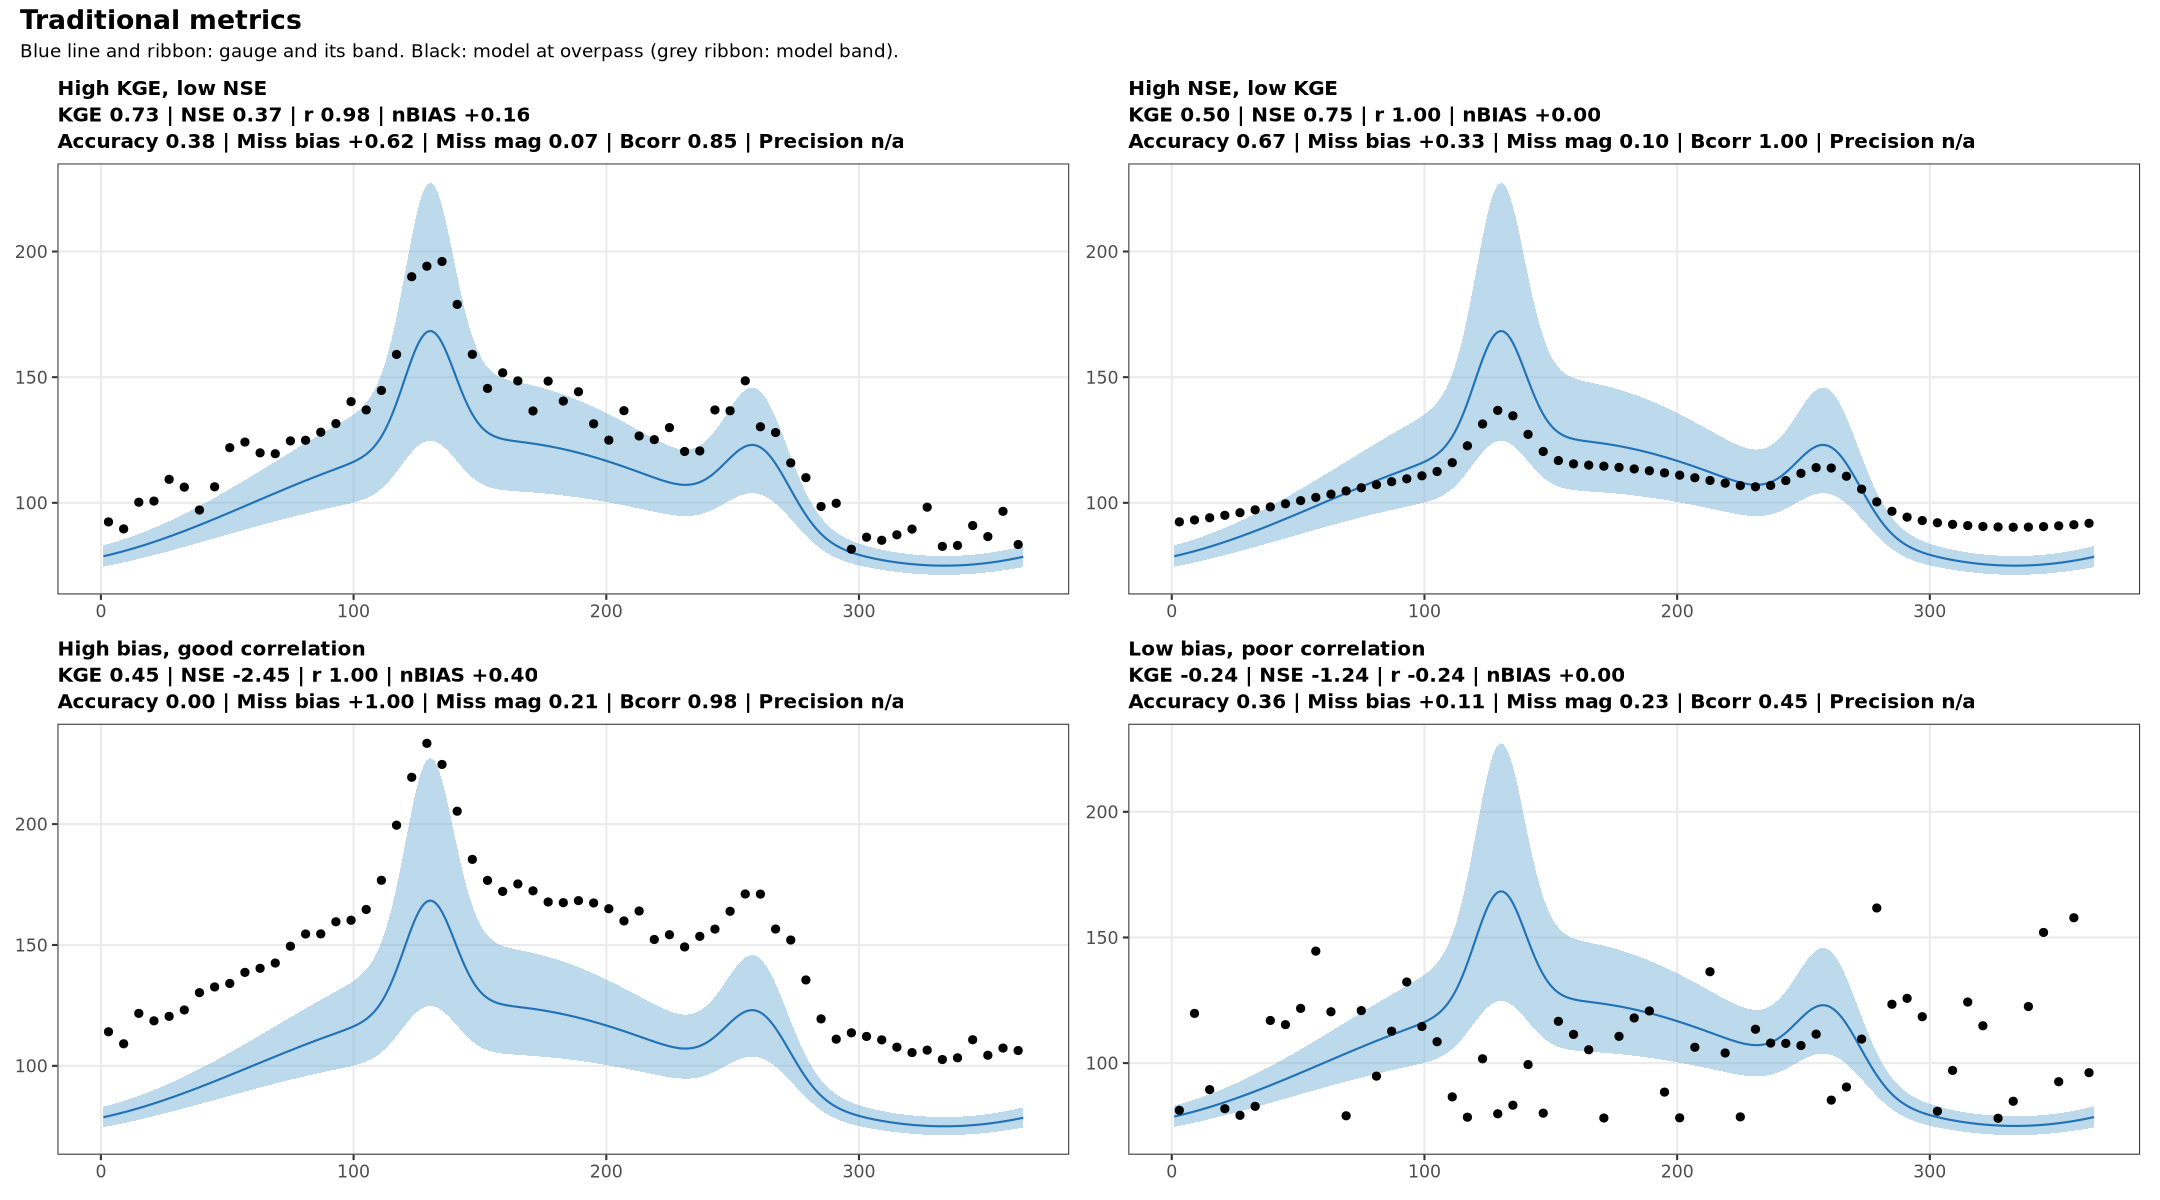

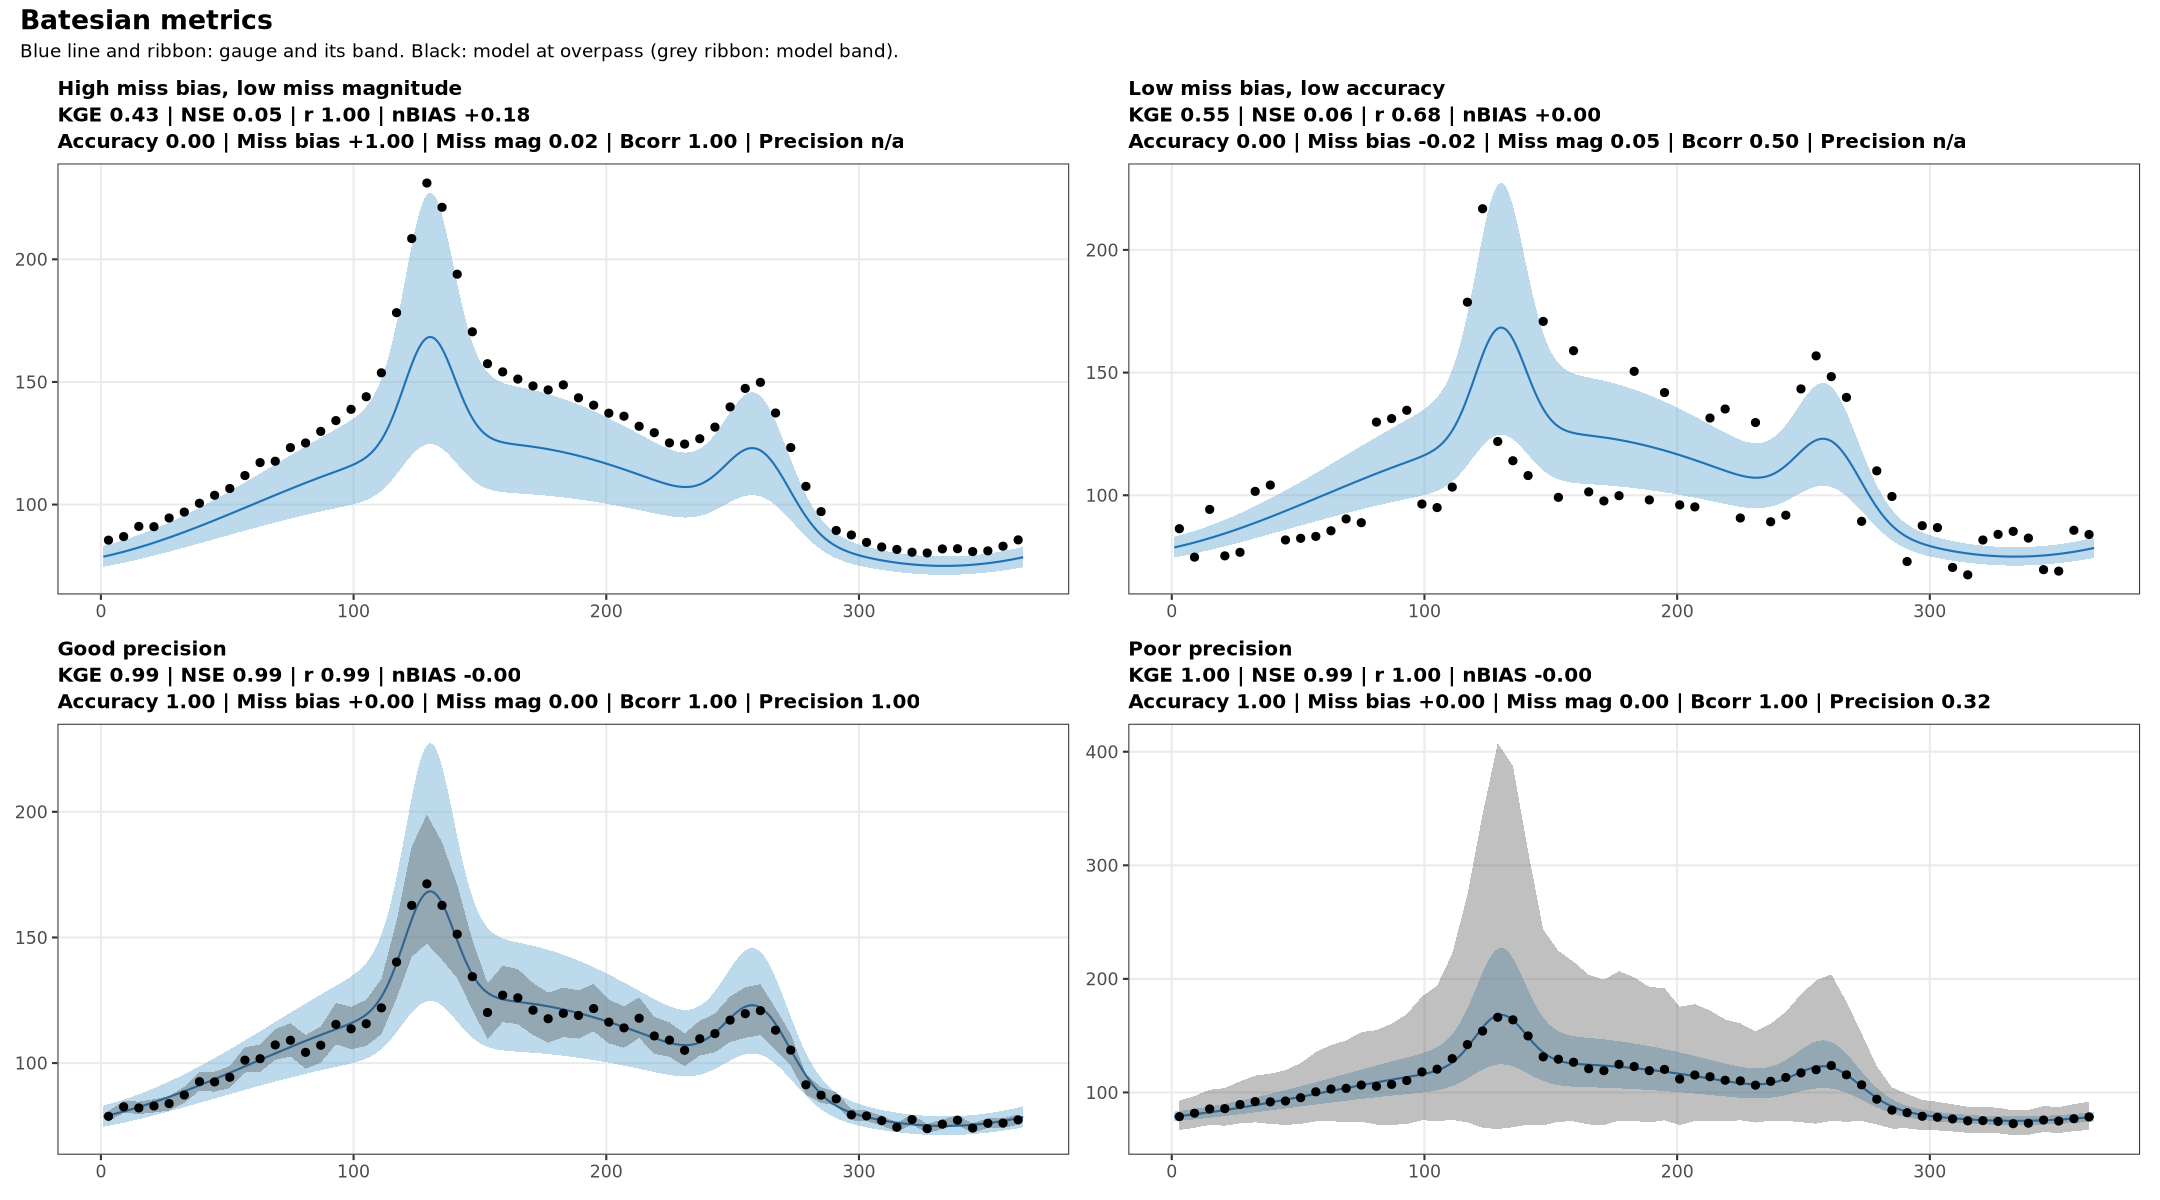

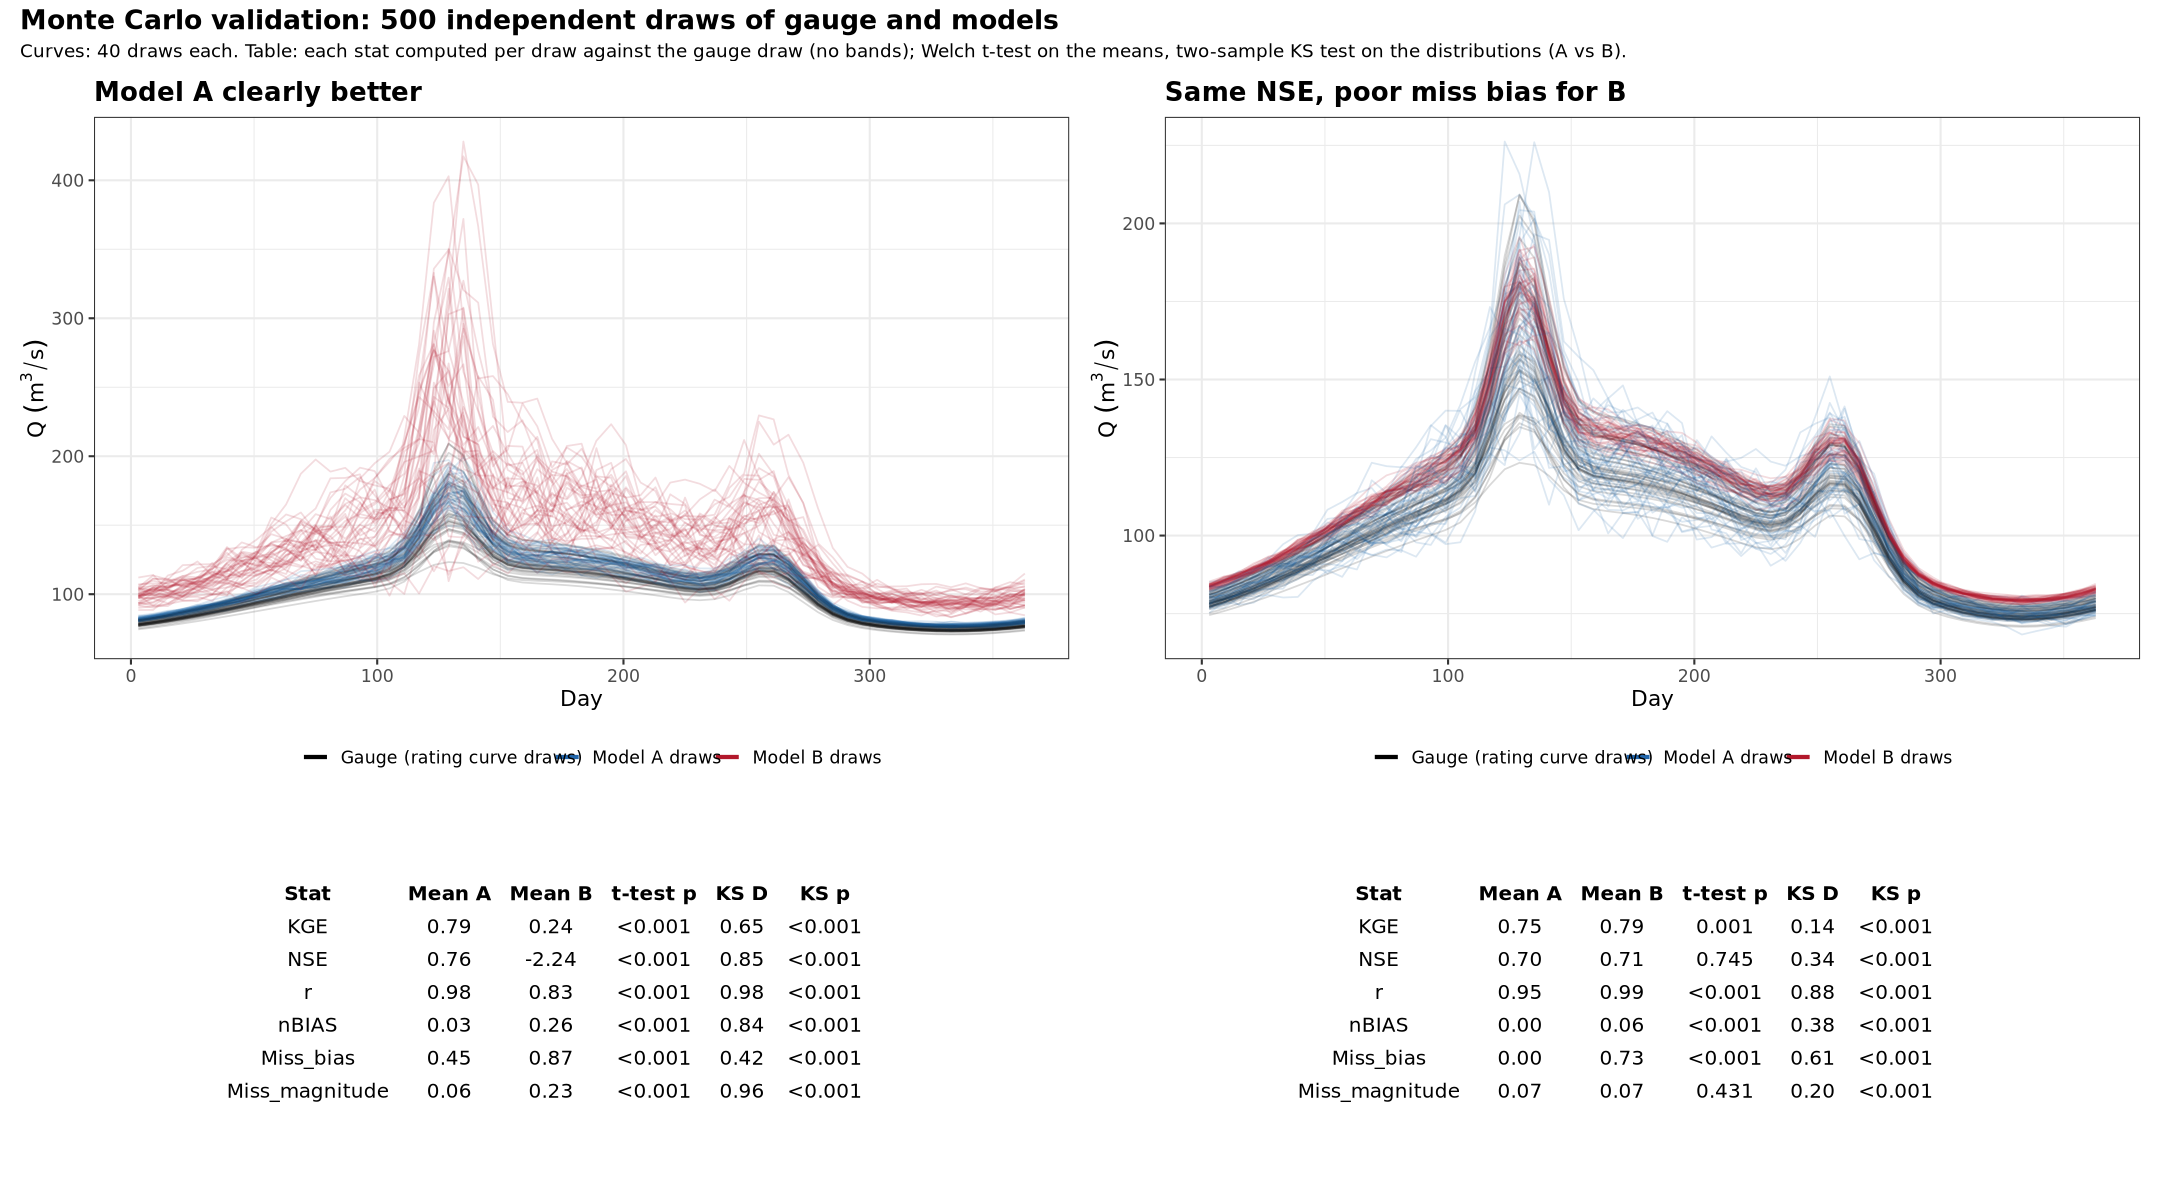

In [12]:
source('/nas/cee-water/cjgleason/colin/Batesian_Validation/make_example_fig.R')

# only needed to rebuild the data; otherwise read the saved rds
# make_example_data('/nas/cee-water/cjgleason/colin/Batesian_Validation/example_data_for_example_fig.rds')

example_figs <- plot_example_figs(readRDS('/nas/cee-water/cjgleason/colin/Batesian_Validation/example_data_for_example_fig.rds'))
options(repr.plot.width = 18, repr.plot.height = 10)
example_figs$trad
example_figs$bates
example_figs$mc

fig_dir <- '/nas/cee-water/cjgleason/colin/Batesian_Validation/Figures'

ggsave(file.path(fig_dir, 'example_trad.png'),  example_figs$trad,  width = 14, height = 10, dpi = 300, bg = 'white')
ggsave(file.path(fig_dir, 'example_bates.png'), example_figs$bates, width = 14, height = 10, dpi = 300, bg = 'white')
ggsave(file.path(fig_dir, 'example_MC.png'),    example_figs$mc,    width = 15, height = 10, dpi = 300, bg = 'white')